#Practical week 4 with solutions: data loaders and a first CNN

##Set up and dataset

We'll start by loading the MNIST dataset. This comes in the form of the `Dataset` class which can subsequently be passed to the `Dataloader` class to make reading random mini-batches easy.



We're using a few more imports here: torchvision contains many useful operations related specifically to images. It also contains some standard datasets in a prepackaged form. Matplotlib is for displaying images.

In [1]:
import torch
import torch.nn as nn
from torchvision import datasets
from torchvision.transforms import ToTensor
import matplotlib.pyplot as plt

Let's set up the datasets - this will download the dataset to the local (colab) file system.

In [2]:
train_data = datasets.MNIST(root = 'data', train = True, transform = ToTensor(), download = True)
test_data = datasets.MNIST(root = 'data', train = False, transform = ToTensor())

100%|██████████| 9.91M/9.91M [00:00<00:00, 37.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 998kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.57MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.45MB/s]


##Splitting the test set into validation and test sets

MNIST comes with 60,000 training images and 10,000 test images. We now split the 10,000 test images 50/50:

- **Validation set (5,000 images)**: used *during* training to check how well the model does on data it has not trained on. We use it to compare training and validation loss, and to make decisions (number of epochs, learning rate, which model). The weights are **never** updated using it.
- **Test set (5,000 images)**: kept locked away until the very end, so that the final accuracy is an honest estimate.

We use a fixed random seed so that everyone gets exactly the same split.

In [3]:
from torch.utils.data import random_split

full_test_data = test_data   # the original 10,000 MNIST test images
generator = torch.Generator().manual_seed(42)   # fixed seed: same split every run
val_data, test_data = random_split(full_test_data, [5000, 5000], generator=generator)

print('Training set:   ', len(train_data))
print('Validation set: ', len(val_data))
print('Test set:       ', len(test_data))

Training set:    60000
Validation set:  5000
Test set:        5000


These are `Dataset` objects. They provide two crucial methods. One returns a length so that `len(train_data)` returns the number of elements in the dataset. Second is `__getitem__` which takes the index of data item as input and returns the item (for example, it might return an image and the corresponding label). Later, we will write our own custom dataset.

In [4]:
image, label = train_data.__getitem__(0)
# Or equivalently: image, label = train_data[0]
print(image.shape)
print(label)

torch.Size([1, 28, 28])
5


Datasets can be used with a `Dataloader` as a convenient way to manage requesting random mini-batches and iterating over datasets. The data loader itself is an iterable object that, in this case, returns pairs of input images and corresponding labels of the requested batch size.

In [5]:
train_loader = torch.utils.data.DataLoader(train_data, batch_size=100, shuffle=True, num_workers=0)
val_loader = torch.utils.data.DataLoader(val_data, batch_size=100, shuffle=False, num_workers=0)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=100, shuffle=True, num_workers=0)

Now that we have a dataset and dataloader, let's take a look at some of the data in our dataset. We'll load a random mini-batch and then display the first 25 images along with their labels.

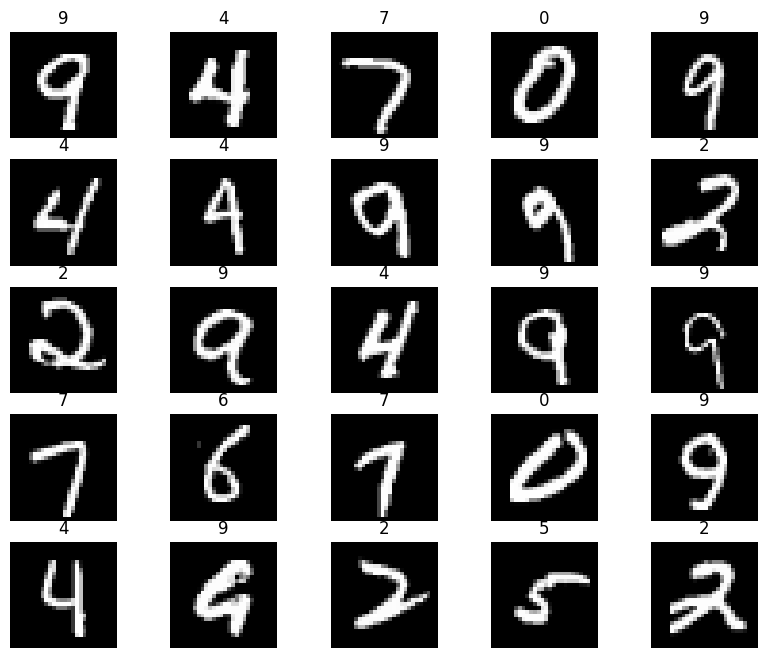

In [6]:
images, labels = next(iter(train_loader))

figure = plt.figure(figsize=(10, 8))
cols, rows = 5, 5
for i in range(cols * rows):
    figure.add_subplot(rows, cols, i+1)
    plt.title(labels[i].item())
    plt.axis("off")
    plt.imshow(images[i,:].squeeze(), cmap="gray")
plt.show()

##Defining the network

In [7]:
class LeNet(nn.Module):
    def __init__(self):
        super(LeNet, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=6, kernel_size=5, stride=1, padding=2)
        self.sigmoid = nn.Tanh() # LeCun actually uses hyperbolic tangent, though the paper talks about "sigmoidal function"
        self.meanpool = nn.AvgPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5, stride=1, padding=0)
        self.fc1 = nn.Linear(in_features=5*5*16,out_features=120)
        self.fc2 = nn.Linear(in_features=120,out_features=84)
        self.fc3 = nn.Linear(in_features=84,out_features=10)

    def forward(self, x):
        # Input x has dimensions B x 1 x 28 x 28, B is batch size
        # Comments show tensor size output from previous line
        x = self.conv1(x)
        # B x 6 x 28 x 28
        x = self.sigmoid(x)
        x = self.meanpool(x)
        # B x 6 x 14 x 14
        x = self.conv2(x)
        # B x 16 x 10 x 10
        x = self.sigmoid(x)
        x = self.meanpool(x)
        # B x 16 x 5 x 5
        x = x.view(x.size(0), -1) # As an alternative, you could use a nn.Flatten() layer here
        # Flattened to B x 400
        x = self.fc1(x)
        # B x 120
        x = self.sigmoid(x)
        x = self.fc2(x)
        # B x 84
        x = self.sigmoid(x)
        x = self.fc3(x)
        # B x 10
        return x

# Instantiate the model - this initialises all weights and biases
model = LeNet()

##Helper functions: validation loss and plotting

Two small helpers that we will reuse every time we train a model:

- `evaluate(model, loader, loss_func)` runs the model over a whole data loader **without updating any weights** and returns the average loss and the accuracy.
- `plot_losses(train_losses, val_losses, title)` plots training and validation loss against the epoch number so we can compare them.

In [9]:
def evaluate(model, loader, loss_func, regression=False):
    """Average loss and accuracy of `model` over every batch in `loader`. No weights are updated."""
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            output = model(images)
            if regression:
                loss = loss_func(output, labels.unsqueeze(1).float())
                pred_y = torch.round(output).squeeze(1)   # round to get the predicted digit
            else:
                loss = loss_func(output, labels)
                pred_y = torch.argmax(output, 1)
            total_loss += loss.item() * labels.size(0)
            correct += (pred_y == labels).sum().item()
            total += labels.size(0)
    model.train()
    return total_loss / total, correct / total


def plot_losses(train_losses, val_losses, title):
    epochs = list(range(1, len(train_losses) + 1))
    plt.figure(figsize=(7, 4))
    plt.plot(epochs, train_losses, 'o-', label='Training loss')
    plt.plot(epochs, val_losses, 's-', label='Validation loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title(title)
    plt.xticks(epochs)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

##Training

Different to previous practicals, we are using random mini-batches here. This means we have two loops, an outer one over "epochs" (an epoch means every training element has been seen once) and an inner one over random mini-batches as provided by the data loader. This will take a few minutes to run.

At the end of every epoch we also compute the loss on the **validation set** (images the model has never trained on) and store it next to the training loss. After training we plot both curves to compare them.

In [10]:
num_epochs = 10

optim = torch.optim.SGD(model.parameters(), lr = 0.1)
iterations_per_epoch = len(train_loader)

# Set up the loss function
loss_func = nn.CrossEntropyLoss()

# One value per epoch, so that we can plot them afterwards
train_losses = []
val_losses = []

for epoch in range(num_epochs):
  # ---- Training: update the weights using the training set ----
  total_loss = 0
  for i, (images, labels) in enumerate(train_loader):
    output = model(images)
    loss = loss_func(output,labels)
    optim.zero_grad()
    loss.backward()
    optim.step()
    if (i+1) % 100 == 0:
       print('Epoch [{}/{}], Iteration [{}/{}], Loss: {:.4f}'.format(epoch + 1, num_epochs, i + 1, iterations_per_epoch, loss.item()))
    total_loss += loss.item()   # .item() so we do not keep the whole computation graph in memory

  # ---- Validation: measure the loss on the validation set. No weights are updated ----
  train_loss = total_loss / iterations_per_epoch   # average loss per mini-batch over the epoch
  val_loss, val_acc = evaluate(model, val_loader, loss_func)
  train_losses.append(train_loss)
  val_losses.append(val_loss)
  print('Epoch [{}/{}] done: training loss {:.4f}, validation loss {:.4f}, validation accuracy {:.2%}'.format(epoch+1, num_epochs, train_loss, val_loss, val_acc))

Epoch [1/10], Iteration [100/600], Loss: 0.9144
Epoch [1/10], Iteration [200/600], Loss: 0.4484
Epoch [1/10], Iteration [300/600], Loss: 0.2676
Epoch [1/10], Iteration [400/600], Loss: 0.4670
Epoch [1/10], Iteration [500/600], Loss: 0.2693
Epoch [1/10], Iteration [600/600], Loss: 0.2361
Epoch [1/10] done: training loss 0.6019, validation loss 0.2038, validation accuracy 94.26%
Epoch [2/10], Iteration [100/600], Loss: 0.1110
Epoch [2/10], Iteration [200/600], Loss: 0.2689
Epoch [2/10], Iteration [300/600], Loss: 0.1594
Epoch [2/10], Iteration [400/600], Loss: 0.2513
Epoch [2/10], Iteration [500/600], Loss: 0.1715
Epoch [2/10], Iteration [600/600], Loss: 0.1994
Epoch [2/10] done: training loss 0.1681, validation loss 0.1117, validation accuracy 96.76%
Epoch [3/10], Iteration [100/600], Loss: 0.1051
Epoch [3/10], Iteration [200/600], Loss: 0.0494
Epoch [3/10], Iteration [300/600], Loss: 0.0776
Epoch [3/10], Iteration [400/600], Loss: 0.1619
Epoch [3/10], Iteration [500/600], Loss: 0.0719


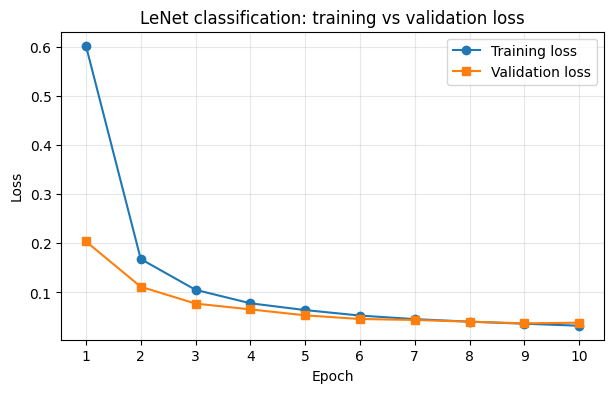

In [11]:
plot_losses(train_losses, val_losses, 'LeNet classification: training vs validation loss')

Do you think this has converged after 10 epochs? If not, don't run any more for now. See how it performs below then come back and run more if you think performance is still improving.

Look at the plot above to decide:
- Both curves still falling: the model is still learning, so more epochs should help.
- Training loss keeps falling but validation loss flattens or rises: the model is starting to **overfit** (memorising the training set). More epochs will not help.
- A large gap between the two curves is another sign of overfitting.

##Evaluation

Now that training is finished, let's see how well it performs on the **test set**: the 5,000 images that were not used for training and not used for choosing anything. We only look at the test set once, here at the end.

In [12]:
test_loss, test_acc = evaluate(model, test_loader, loss_func)
print('Test accuracy of the model on the {} test images: {:.2%} (test loss {:.4f})'.format(len(test_data), test_acc, test_loss))

Test accuracy of the model on the 5000 test images: 98.28% (test loss 0.0497)


Pretty amazing huh?! A pretty simple convolutional neural network, a couple of minutes training in your web browser and you can classify thousands of hand written digits in a few seconds with nearly 100% accuracy! Yann LeCun got to 99.05% test set accuracy with this architecture. You could also get there if you tuned hyperparameters a bit (number of epochs, learning rate, batch size, what optimiser you use).

But before you try to improve it, let's see some examples that it is classifying. This code will display 25 images from the test set, the true label and the classification predicted by your trained network. Each time you run the following code block you'll get results from a new batch. So run it a few times. You should see a few impressive results where it does well on hard examples but also look out for mistakes. Can you guess why it failed on that input?

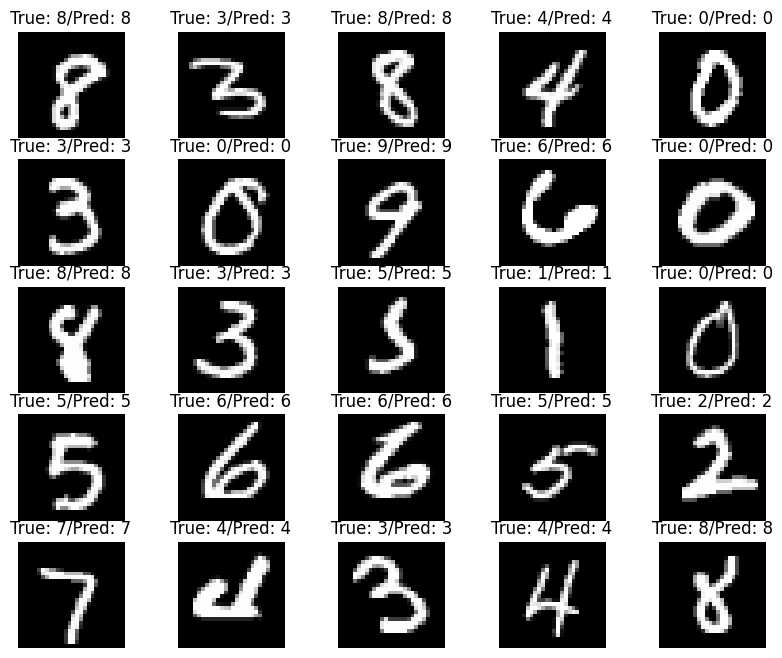

In [13]:
# Run a test batch through the network
images, labels = next(iter(test_loader))
output = model(images)
pred_y = torch.argmax(output, 1)

# Display first 25 images with predicted labels
figure = plt.figure(figsize=(10, 8))
for i in range(25):
    figure.add_subplot(5, 5, i+1)
    plt.title("True: {}/Pred: {}".format(labels[i].item(),pred_y[i].item()))
    plt.axis("off")
    plt.imshow(images[i,:].squeeze(), cmap="gray")
plt.show()

##Visualising the learnt filters

The first convolution layer in the model learns six single channel $5\times 5$ filters. Let's visualise them to see what they've learnt.

**To do**:

Extract the learnt filters from the conv1 layer of model. Display them as grayscale images.

##Solution

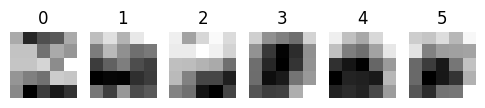

In [14]:
figure = plt.figure(figsize=(6, 1))
for i in range(6):
    figure.add_subplot(1, 6, i+1)
    plt.title(i)
    plt.axis("off")
    plt.imshow(model.conv1.weight[i,:].squeeze().detach(), cmap="gray")
plt.show()

##Visualising the feature maps

As data is passed through a CNN, the tensor after each convolutional layer is referred to as a "feature map" as it still has spatial dimensions (i.e. the tensor will have shape $B\times C\times H\times W$, where $B$ is batch size, $C$ is the number of channels output by that layer and $H$ and $W$ are the height and width of the output tensor).

**To do**:

Write some code to visualise the feature maps as gray scale images. i.e. you should be able to specify a layer and channel and then display this as an image. Display a test input image and then explore the feature maps at different layers. Can you get an impression of what features it is learning?

##Solution

The easiest way to do this is to start with an input tensor and manually pass it through the layers of the network.

torch.Size([1, 6, 28, 28])


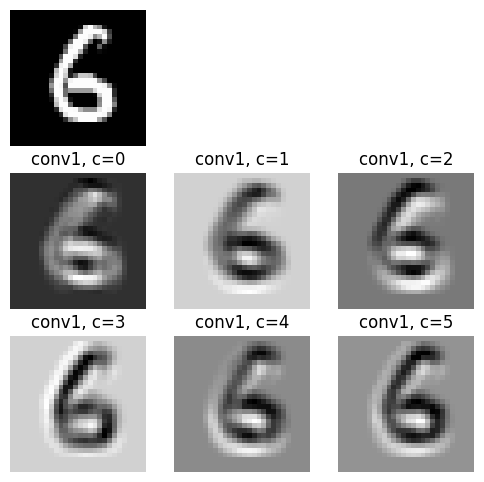

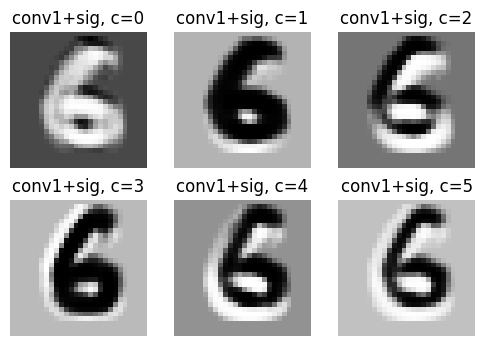

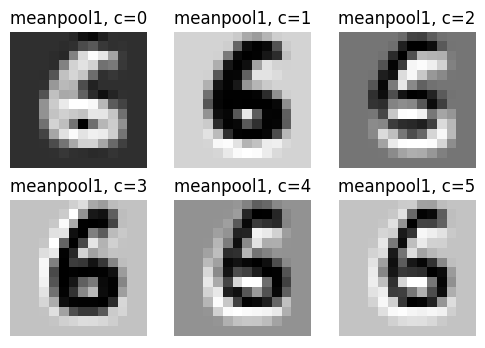

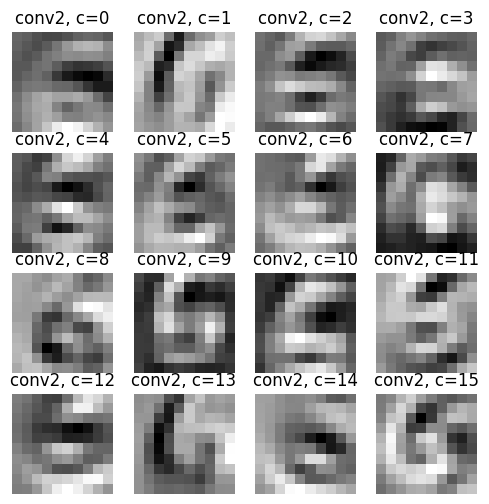

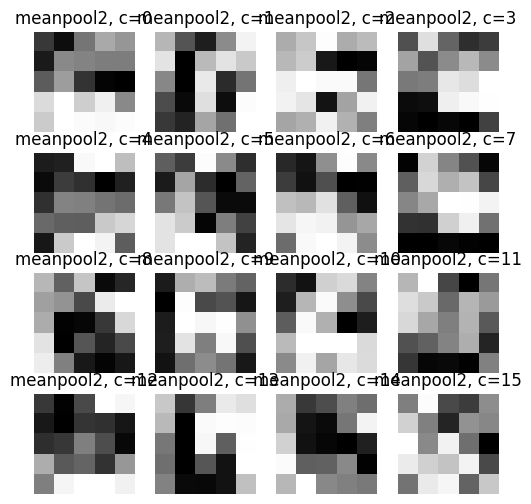

In [15]:
# Grab a random image
images, labels = next(iter(test_loader))
image = images[0,:,:,:].unsqueeze(0) # Take only first image in random batch and unsqueeze to keep size 1 x 1 x 28 x 28

# Pass image through first conv layer
x = model.conv1(image)
print(x.shape)

figure = plt.figure(figsize=(6,6))
figure.add_subplot(3, 3, 1)
plt.imshow(image[0,0,:,:], cmap="gray")
plt.axis("off")
for i in range(6):
    figure.add_subplot(3, 3, i+4)
    plt.axis("off")
    plt.title('conv1, c={}'.format(i))
    plt.imshow(x[0,i,:,:].detach().numpy(), cmap="gray")
plt.show()

x = model.sigmoid(x)

figure = plt.figure(figsize=(6,4))
plt.axis("off")
for i in range(6):
    figure.add_subplot(2, 3, i+1)
    plt.axis("off")
    plt.title('conv1+sig, c={}'.format(i))
    plt.imshow(x[0,i,:,:].detach().numpy(), cmap="gray")
plt.show()

x = model.meanpool(x)

figure = plt.figure(figsize=(6,4))
plt.axis("off")
for i in range(6):
    figure.add_subplot(2, 3, i+1)
    plt.axis("off")
    plt.title('meanpool1, c={}'.format(i))
    plt.imshow(x[0,i,:,:].detach().numpy(), cmap="gray")
plt.show()

x = model.conv2(x)

figure = plt.figure(figsize=(6,6))
plt.axis("off")
for i in range(16):
    figure.add_subplot(4, 4, i+1)
    plt.axis("off")
    plt.title('conv2, c={}'.format(i))
    plt.imshow(x[0,i,:,:].detach().numpy(), cmap="gray")
plt.show()

x = model.sigmoid(x)
x = model.meanpool(x)

figure = plt.figure(figsize=(6,6))
plt.axis("off")
for i in range(16):
    figure.add_subplot(4, 4, i+1)
    plt.axis("off")
    plt.title('meanpool2, c={}'.format(i))
    plt.imshow(x[0,i,:,:].detach().numpy(), cmap="gray")
plt.show()


Or here's a fancier solution that uses forward hooks to get the output from any named layer and specified channel number.

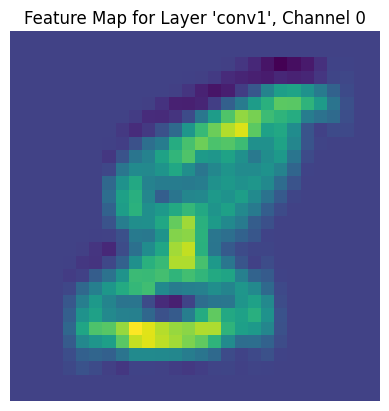

In [16]:
def visualize_feature_map(model, layer_name, channel, input_tensor):
    # Get the specified layer
    layer = None
    for name, module in model.named_modules():
        if name == layer_name:
            layer = module
            break

    if layer is None:
        print(f"Layer '{layer_name}' not found in the model.")
        return

    # Forward pass to get the feature map
    activations = None
    def hook(module, input, output):
        nonlocal activations
        activations = output
    hook_handle = layer.register_forward_hook(hook)

    # Dummy input to run forward pass
    model.eval()
    with torch.no_grad():
        model(input_tensor)

    # Remove the hook
    hook_handle.remove()

    # Get the feature map for the specified channel
    feature_map = activations[:, channel, :, :]

    # Convert to numpy array and plot
    plt.imshow(feature_map.squeeze().cpu(), cmap='viridis')
    plt.title(f"Feature Map for Layer '{layer_name}', Channel {channel}")
    plt.axis('off')
    plt.show()

images, labels = next(iter(train_loader))
input_tensor = images[0,:].unsqueeze(0)
visualize_feature_map(model, 'conv1', 0, input_tensor)


##Digit recognition as a regression problem

The standard way to solve the MNIST digit recognition task is as a classification task, i.e. for an input image, choose one from 10 discrete classes. We will now try to solve the task as a *regression problem*.

**To do**:

The goal is to modify the above model and training code such that the model outputs a single scalar value which should be close to the value of the actual digit. For example, if the input digit has label 4, if the model outputs 4.2, this would be a pretty good answer (and could be rounded to 4). You will need to:

1. Modify the model to have only a single output.
2. Think about the activation/post-processing you will apply to the final output. You know that your digits lie in the range 0 to 9. Can you think of a way to force the network output into this range? (Hint: remember what `torch.nn.sigmoid` does).
3. Modify the loss function. The labels are classes per input image. Your network will now output a continuous scalar value. You want to penalise larger errors more (e.g. predicting 0.4 when the label is 9 is really bad but predicting 4.2 when the label is 5 is not so bad).
4. You may need to tweak hyperparameters like learning rate now that you have a very different loss and network output.
5. Check that training loss reduces during training. Can you compute an accuracy percentage like we did for classification? (Hint: round the output). How does it compare to the classification solution?
6. Modify the code for visualising input images and predicted labels to show the continuous label.

##Solutions

Here are my solutions. I stuck with the original LeNet architecture (I could get slightly better results using ReLU activation and max pooling but it didn't make much difference). I used tanh activation at the output which meant my output was in the range -1..1. So I then add 1 and multiply by 4.5 to get in the range 0..9. There are a few "gotchas" to watch out for.

1. The labels need converting to floats before you can compute the loss.
2. This one *really* caught me out. `output` has shape $100\times 1$ whereas  `labels` has shape $100$, i.e. it is 1D. If you pass them to MSELoss, it doesn't complain and it worked correctly with BCELoss. However, it isn't doing what you think it's doing! It expands `labels` to shape $1\times 100$ and then computes errors between all pairs of values and labels! This gives you a meaningless loss. To illustrate what I mean, look at this code block:

In [17]:
x = torch.randn(100,1)
y = torch.randn(100,)
print(x.shape)
print(y.shape)
z = x-y
print(z.shape)

torch.Size([100, 1])
torch.Size([100])
torch.Size([100, 100])


The reason for this is to do with the way PyTorch handles operations on pairs of tensors with different shapes. Read about PyTorch broadcasting semantics [here](https://pytorch.org/docs/stable/notes/broadcasting.html).

So, you need to be really careful to make sure everything is the same shape before passing to the loss function. Specifically you should unsqueeze `labels` in `dim=1`. Both the above issues are handled by the line `loss = loss_func(output,labels.unsqueeze(1).float())`. In general, when you're debugging, be sure to print the shape of everything. This bug was particularly hard to spot as it didn't cause an error but meant the network couldn't learn anything. I was suspicious when the loss just didn't reduce.

3. MSELoss on values between 0 and 9 results in large losses and large gradients. This makes training more unstable. I needed to reduce the learning rate to 0.01.

In [18]:
class LeNetRegression(nn.Module):
    def __init__(self):
        super(LeNetRegression, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=6, kernel_size=5, stride=1, padding=2)
        self.sigmoid = nn.Tanh() # LeCun actually uses hyperbolic tangent, though the paper talks about "sigmoidal function"
        self.meanpool = nn.AvgPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5, stride=1, padding=0)
        self.fc1 = nn.Linear(in_features=5*5*16,out_features=120)
        self.fc2 = nn.Linear(in_features=120,out_features=84)
        self.fc3 = nn.Linear(in_features=84,out_features=1)

    def forward(self, x):
        # Input x has dimensions B x 1 x 28 x 28, B is batch size
        # Comments show tensor size output from previous line
        x = self.conv1(x)
        # B x 6 x 28 x 28
        x = self.sigmoid(x)
        x = self.meanpool(x)
        # B x 6 x 14 x 14
        x = self.conv2(x)
        # B x 16 x 10 x 10
        x = self.sigmoid(x)
        x = self.meanpool(x)
        # B x 16 x 5 x 5
        x = x.view(x.size(0), -1)
        # Flattened to B x 400
        x = self.fc1(x)
        # B x 120
        x = self.sigmoid(x)
        x = self.fc2(x)
        # B x 84
        x = self.sigmoid(x)
        x = self.fc3(x)
        # B x 1
        x = self.sigmoid(x) # This maps to -1..1
        x = (x+1)*4.5 # After rescaling, the value is now in 0..9
        return x

# Instantiate the model - this initialises all weights and biases
model = LeNetRegression()

In [19]:
num_epochs = 10

optim = torch.optim.SGD(model.parameters(), lr = 0.01)
iterations_per_epoch = len(train_loader)

# Set up the loss function
loss_func = nn.MSELoss()

# One value per epoch, so that we can plot them afterwards
reg_train_losses = []
reg_val_losses = []

for epoch in range(num_epochs):
  # ---- Training: update the weights using the training set ----
  total_loss = 0
  for i, (images, labels) in enumerate(train_loader):
    output = model(images)
    loss = loss_func(output,labels.unsqueeze(1).float())
    optim.zero_grad()
    loss.backward()
    optim.step()
    if (i+1) % 100 == 0:
       print('Epoch [{}/{}], Iteration [{}/{}], Loss: {:.4f}'.format(epoch + 1, num_epochs, i + 1, iterations_per_epoch, loss.item()))
    total_loss += loss.item()   # .item() so we do not keep the whole computation graph in memory

  # ---- Validation: measure the loss on the validation set. No weights are updated ----
  train_loss = total_loss / iterations_per_epoch   # average loss per mini-batch over the epoch
  val_loss, val_acc = evaluate(model, val_loader, loss_func, regression=True)
  reg_train_losses.append(train_loss)
  reg_val_losses.append(val_loss)
  print('Epoch [{}/{}] done: training loss {:.4f}, validation loss {:.4f}, validation accuracy {:.2%}'.format(epoch+1, num_epochs, train_loss, val_loss, val_acc))

Epoch [1/10], Iteration [100/600], Loss: 4.9251
Epoch [1/10], Iteration [200/600], Loss: 3.5170
Epoch [1/10], Iteration [300/600], Loss: 3.7578
Epoch [1/10], Iteration [400/600], Loss: 3.0007
Epoch [1/10], Iteration [500/600], Loss: 2.1317
Epoch [1/10], Iteration [600/600], Loss: 2.9004
Epoch [1/10] done: training loss 3.4799, validation loss 2.9083, validation accuracy 30.86%
Epoch [2/10], Iteration [100/600], Loss: 2.4327
Epoch [2/10], Iteration [200/600], Loss: 1.8682
Epoch [2/10], Iteration [300/600], Loss: 1.1080
Epoch [2/10], Iteration [400/600], Loss: 1.2318
Epoch [2/10], Iteration [500/600], Loss: 0.8737
Epoch [2/10], Iteration [600/600], Loss: 0.6174
Epoch [2/10] done: training loss 1.4549, validation loss 0.9874, validation accuracy 56.48%
Epoch [3/10], Iteration [100/600], Loss: 0.5208
Epoch [3/10], Iteration [200/600], Loss: 0.8651
Epoch [3/10], Iteration [300/600], Loss: 0.6727
Epoch [3/10], Iteration [400/600], Loss: 0.4876
Epoch [3/10], Iteration [500/600], Loss: 0.5640


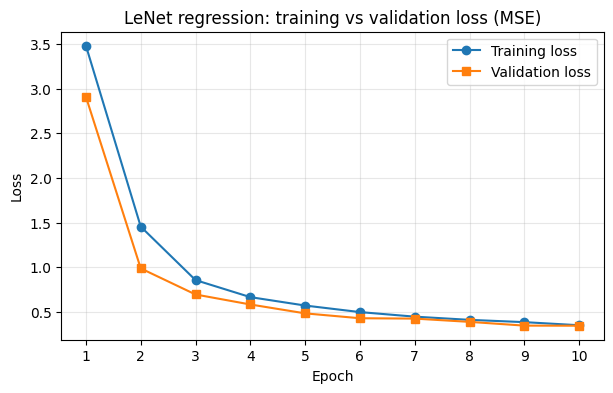

In [20]:
plot_losses(reg_train_losses, reg_val_losses, 'LeNet regression: training vs validation loss (MSE)')

In [23]:
test_loss, test_acc = evaluate(model, test_loader, loss_func, regression=True)
print('Test accuracy of the model on the {} test images: {:.2%} (test MSE {:.4f})'.format(len(test_data), test_acc, test_loss))

Test accuracy of the model on the 5000 test images: 86.40% (test MSE 0.4563)


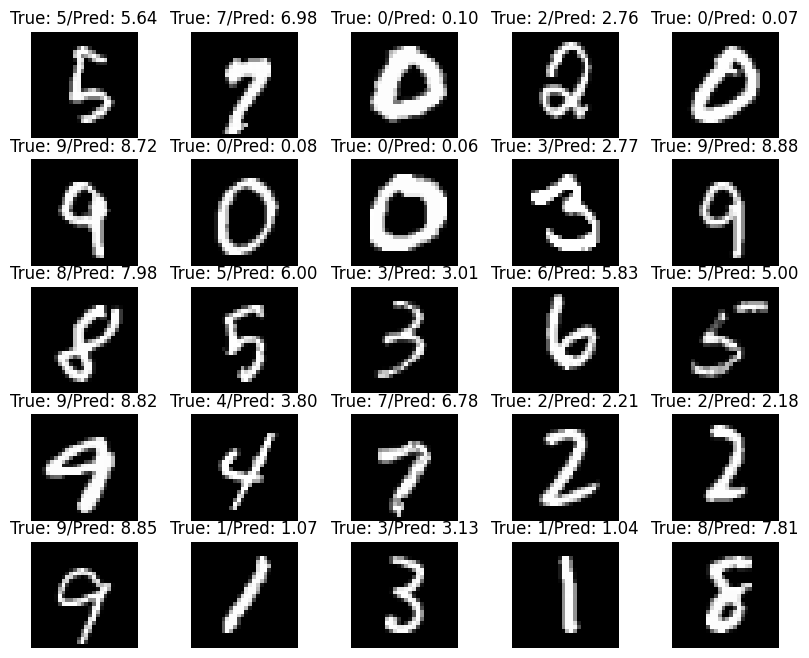

In [24]:
# Run a test batch through the network
images, labels = next(iter(test_loader))
output = model(images)

# Display first 25 images with predicted labels
figure = plt.figure(figsize=(10, 8))
for i in range(25):
    figure.add_subplot(5, 5, i+1)
    plt.title("True: {}/Pred: {:.2f}".format(labels[i].item(),output[i].item()))
    plt.axis("off")
    plt.imshow(images[i,:].squeeze(), cmap="gray")
plt.show()

## Improving the model (highly recommended for Masters-level students)

**To do**:

Now it's time to implement your own alternative model to LeNet (the classification version). I would like you to implement a mini version of the VGG network described in the video lecture. Specifically, aim for more depth (in terms of more convolutional layers) but use $3\times 3$ filters instead of $5\times 5$. Also, use ReLU instead of sigmoid activation and max pooling instead of mean pooling. You can decide how many feature channels to have at each layer. Can you match or improve on the LeNet model performance? Be careful not to add too many parameters overall so that you start overfitting to the training data and making test performance worse.

In [25]:
class miniVGG(nn.Module):
    def __init__(self):
        super(miniVGG, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=6, kernel_size=3, stride=1, padding=1)
        self.relu = nn.ReLU()
        self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(in_channels=6, out_channels=12, kernel_size=3, stride=1, padding=1)
        self.conv3 = nn.Conv2d(in_channels=12, out_channels=24, kernel_size=3, stride=1, padding=0)

        self.fc1 = nn.Linear(in_features=5*5*24,out_features=120)
        self.fc2 = nn.Linear(in_features=120,out_features=84)
        self.fc3 = nn.Linear(in_features=84,out_features=10)

    def forward(self, x):
        # Input x has dimensions B x 1 x 28 x 28, B is batch size
        # Comments show tensor size output from previous line
        x = self.conv1(x)
        # B x 6 x 28 x 28
        x = self.relu(x)
        x = self.maxpool(x)
        # B x 6 x 14 x 14
        x = self.conv2(x)
        # B x 12 x 14 x 14
        x = self.relu(x)
        x = self.maxpool(x)
        # B x 12 x 7 x 7
        x = self.conv3(x)
        # B x 24 x 5 x 5
        x = self.relu(x)
        x = x.view(x.size(0), -1)
        # Flattened to B x 600
        x = self.fc1(x)
        x = self.relu(x)
        # B x 120
        x = self.fc2(x)
        x = self.relu(x)
        # B x 84
        x = self.fc3(x)
        # B x 10
        return x

model = miniVGG()

###Training miniVGG with validation

Same recipe as before: train on the training set, check the loss on the validation set after every epoch, then plot both curves. If your miniVGG has many more parameters than LeNet, watch the gap between the curves: that is where overfitting shows up first.

In [26]:
num_epochs = 10

optim = torch.optim.SGD(model.parameters(), lr = 0.01, momentum = 0.9)
iterations_per_epoch = len(train_loader)

# Set up the loss function
loss_func = nn.CrossEntropyLoss()

# One value per epoch, so that we can plot them afterwards
vgg_train_losses = []
vgg_val_losses = []

for epoch in range(num_epochs):
  # ---- Training: update the weights using the training set ----
  total_loss = 0
  for i, (images, labels) in enumerate(train_loader):
    output = model(images)
    loss = loss_func(output,labels)
    optim.zero_grad()
    loss.backward()
    optim.step()
    if (i+1) % 100 == 0:
       print('Epoch [{}/{}], Iteration [{}/{}], Loss: {:.4f}'.format(epoch + 1, num_epochs, i + 1, iterations_per_epoch, loss.item()))
    total_loss += loss.item()   # .item() so we do not keep the whole computation graph in memory

  # ---- Validation: measure the loss on the validation set. No weights are updated ----
  train_loss = total_loss / iterations_per_epoch   # average loss per mini-batch over the epoch
  val_loss, val_acc = evaluate(model, val_loader, loss_func)
  vgg_train_losses.append(train_loss)
  vgg_val_losses.append(val_loss)
  print('Epoch [{}/{}] done: training loss {:.4f}, validation loss {:.4f}, validation accuracy {:.2%}'.format(epoch+1, num_epochs, train_loss, val_loss, val_acc))

Epoch [1/10], Iteration [100/600], Loss: 2.2526
Epoch [1/10], Iteration [200/600], Loss: 0.5419
Epoch [1/10], Iteration [300/600], Loss: 0.2955
Epoch [1/10], Iteration [400/600], Loss: 0.2103
Epoch [1/10], Iteration [500/600], Loss: 0.3167
Epoch [1/10], Iteration [600/600], Loss: 0.1162
Epoch [1/10] done: training loss 0.7879, validation loss 0.1464, validation accuracy 95.66%
Epoch [2/10], Iteration [100/600], Loss: 0.1749
Epoch [2/10], Iteration [200/600], Loss: 0.1011
Epoch [2/10], Iteration [300/600], Loss: 0.1086
Epoch [2/10], Iteration [400/600], Loss: 0.1600
Epoch [2/10], Iteration [500/600], Loss: 0.1011
Epoch [2/10], Iteration [600/600], Loss: 0.1909
Epoch [2/10] done: training loss 0.1367, validation loss 0.0920, validation accuracy 97.26%
Epoch [3/10], Iteration [100/600], Loss: 0.1474
Epoch [3/10], Iteration [200/600], Loss: 0.0431
Epoch [3/10], Iteration [300/600], Loss: 0.1354
Epoch [3/10], Iteration [400/600], Loss: 0.1627
Epoch [3/10], Iteration [500/600], Loss: 0.0789


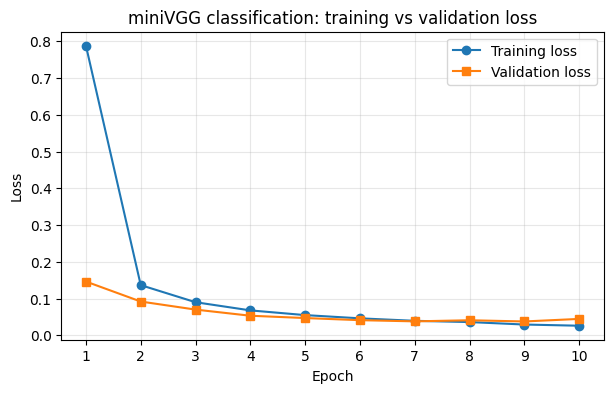

In [27]:
plot_losses(vgg_train_losses, vgg_val_losses, 'miniVGG classification: training vs validation loss')

In [28]:
test_loss, test_acc = evaluate(model, test_loader, loss_func)
print('Test accuracy of miniVGG on the {} test images: {:.2%} (test loss {:.4f})'.format(len(test_data), test_acc, test_loss))

Test accuracy of miniVGG on the 5000 test images: 98.20% (test loss 0.0589)
